In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('automobileEDA.csv')
df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450,13.055556,Medium,0,1


In [4]:
df.shape

(201, 29)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non-null    st

# Question 1

In [ ]:
# Numerical variables
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

# Categorical variables
categorical_columns = df.select_dtypes(include='object').columns.tolist()

print("Numerical variables:", numerical_columns)
print("\nNumber of numerical variables:", len(numerical_columns))

print("\nCategorical variables:", categorical_columns)
print("\nNumber of categorical variables:", len(categorical_columns))

Numerical variables: ['symboling', 'normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'city-L/100km', 'diesel', 'gas']

Number of numerical variables: 19

Categorical variables: ['make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system', 'horsepower-binned']

Number of categorical variables: 10


C:\Users\KEVINNAKITENDE\AppData\Local\Temp\ipykernel_28532\828738297.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include='object').columns.tolist()


In [15]:
df.isnull().sum()


symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64

Stroke has 4 missing values while horsepower has 1 missing value.

In [18]:
#Checking for duplicates
duplicates = df.duplicated()
print(df[duplicates])


Empty DataFrame
Columns: [symboling, normalized-losses, make, aspiration, num-of-doors, body-style, drive-wheels, engine-location, wheel-base, length, width, height, curb-weight, engine-type, num-of-cylinders, engine-size, fuel-system, bore, stroke, compression-ratio, horsepower, peak-rpm, city-mpg, highway-mpg, price, city-L/100km, horsepower-binned, diesel, gas]
Index: []


There are no duplicates in this dataset.

In [9]:
vars = ['price', 'horsepower', 'engine-size',
    'curb-weight','peak-rpm', 'wheel-base']

In [10]:
outliers = []
for var in vars:
    Q1 = df[var].quantile(0.25)
    Q3 = df[var].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers_var = df[(df[var] < lower_bound) | (df[var] > upper_bound)]
    outliers.append({'Variable': var, 'Number of Outliers': len(outliers_var), 'Lower Bound': lower_bound, 'Upper Bound': upper_bound})
outliers_df = pd.DataFrame(outliers)
outliers_df.sort_values(by='Number of Outliers', ascending=False)

,Variable,Number of Outliers,Lower Bound,Upper Bound
0,price,14,-5312.50,29587.50
2,engine-size,10,33.50,205.50
1,horsepower,5,1.00,185.00
5,wheel-base,3,82.65,114.25
3,curb-weight,2,1033.50,4061.50
4,peak-rpm,2,3750.00,6550.00


In [11]:
# Identify potential price outliers

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

price_outliers = df[df['price'] > upper_bound]

# Display relevant automobile characteristics
price_outliers[
    ['make', 'body-style', 'drive-wheels',
     'engine-size', 'horsepower', 'curb-weight', 'price']
].sort_values(by='price', ascending=False)

,make,body-style,drive-wheels,engine-size,horsepower,curb-weight,price
71,mercedes-benz,hardtop,rwd,304,184.0,3715,45400
15,bmw,sedan,rwd,209,182.0,3380,41315
70,mercedes-benz,sedan,rwd,308,184.0,3900,40960
125,porsche,convertible,rwd,194,207.0,2800,37028
16,bmw,sedan,rwd,209,182.0,3505,36880
46,jaguar,sedan,rwd,326,262.0,3950,36000
45,jaguar,sedan,rwd,258,176.0,4066,35550
69,mercedes-benz,convertible,rwd,234,155.0,3685,35056
68,mercedes-benz,sedan,rwd,234,155.0,3740,34184
124,porsche,hardtop,rwd,194,207.0,2756,34028


The IQR method identified 14 potential outliers in the price variable. Further examination revealed that these observations belonged to manufacturers such as Mercedes-Benz, BMW, Porsche and Jaguar. The vehicles generally had relatively large engine sizes and higher horsepower, which could explain their higher prices. Therefore, these observations were considered legitimate rather than data errors and were retained in the dataset. 

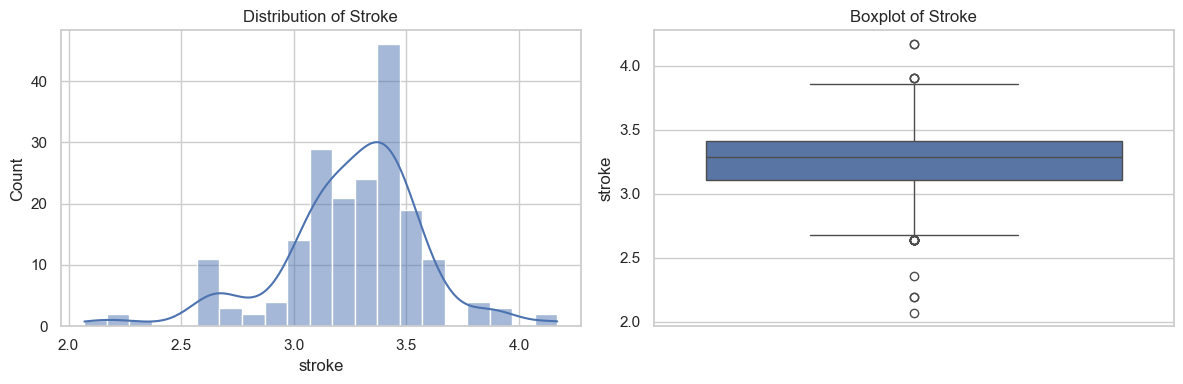

In [13]:
# Examine the distribution of stroke

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['stroke'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of Stroke')

sns.boxplot(y=df['stroke'], ax=axes[1])
axes[1].set_title('Boxplot of Stroke')

plt.tight_layout()
plt.show()

In [14]:
df['stroke'].describe()

count    197.000000
mean       3.256904
std        0.319256
min        2.070000
25%        3.110000
50%        3.290000
75%        3.410000
max        4.170000
Name: stroke, dtype: float64

In [24]:
df['stroke']=df['stroke'].fillna(value=df['stroke'].median())
df.isna().sum()

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64

In [29]:
# Create three equal-width horsepower categories
bins = [47,101,155,262]

group_names = ['Low', 'Medium', 'High']

df['horsepower-binned'] = pd.cut(
    df['horsepower'],
    bins=bins,
    labels=group_names,
    include_lowest=True
)

# Check the resulting categories
print(df['horsepower-binned'].value_counts())

horsepower-binned
Low       115
Medium     62
High       24
Name: count, dtype: int64


In [30]:
df.isna().sum()

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    0
diesel               0
gas                  0
dtype: int64

The horsepower-binned variable contained one missing category despite having an available horsepower measurement. An examination of the original classification revealed that the categories were defined as Low (48–101), Medium (102–155) and High (156–207). However, one automobile had a horsepower value of 262, which fell outside the defined intervals. To address this inconsistency, the upper boundary of the High category was extended to 262 while preserving the original lower category boundaries. The missing category was therefore reconstructed using the corresponding horsepower measurement.

In [32]:
df.to_csv("Nakitende_Data.csv", index=False)

# Question 2

In [33]:
df.describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
count,201.000000,201.00000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,0.840796,122.00000,98.797015,0.837102,0.915126,53.766667,2555.666667,126.875622,3.330692,3.257562,10.164279,103.405534,5117.665368,25.179104,30.686567,13207.129353,9.944145,0.099502,0.900498
std,1.254802,31.99625,6.066366,0.059213,0.029187,2.447822,517.296727,41.546834,0.268072,0.316082,4.004965,37.365700,478.113805,6.423220,6.815150,7947.066342,2.534599,0.300083,0.300083
min,-2.000000,65.00000,86.600000,0.678039,0.837500,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000,4.795918,0.000000,0.000000
25%,0.000000,101.00000,94.500000,0.801538,0.890278,52.000000,2169.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000,7.833333,0.000000,1.000000
50%,1.000000,122.00000,97.000000,0.832292,0.909722,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5125.369458,24.000000,30.000000,10295.000000,9.791667,0.000000,1.000000
75%,2.000000,137.00000,102.400000,0.881788,0.925000,55.500000,2926.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000,12.368421,0.000000,1.000000
max,3.000000,256.00000,120.900000,1.000000,1.000000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000,18.076923,1.000000,1.000000


Summary statistics for continous variables

In [35]:
continuous_vars = [
    'normalized-losses','wheel-base','length',
    'width','height','curb-weight','engine-size',
    'bore','stroke','compression-ratio','horsepower',
    'peak-rpm','city-mpg','highway-mpg','city-L/100km','price'
]
df[continuous_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
normalized-losses,201.0,122.000000,31.996250,65.000000,101.000000,122.000000,137.000000,256.000000
wheel-base,201.0,98.797015,6.066366,86.600000,94.500000,97.000000,102.400000,120.900000
length,201.0,0.837102,0.059213,0.678039,0.801538,0.832292,0.881788,1.000000
width,201.0,0.915126,0.029187,0.837500,0.890278,0.909722,0.925000,1.000000
height,201.0,53.766667,2.447822,47.800000,52.000000,54.100000,55.500000,59.800000
curb-weight,201.0,2555.666667,517.296727,1488.000000,2169.000000,2414.000000,2926.000000,4066.000000
engine-size,201.0,126.875622,41.546834,61.000000,98.000000,120.000000,141.000000,326.000000
bore,201.0,3.330692,0.268072,2.540000,3.150000,3.310000,3.580000,3.940000
stroke,201.0,3.257562,0.316082,2.070000,3.110000,3.290000,3.410000,4.170000
compression-ratio,201.0,10.164279,4.004965,7.000000,8.600000,9.000000,9.400000,23.000000


In [38]:
# Frequency counts for each categorical variable

for column in categorical_columns:

    print(f"\nFrequency distribution of {column}")

    print(df[column].value_counts())


Frequency distribution of make
make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

Frequency distribution of aspiration
aspiration
std      165
turbo     36
Name: count, dtype: int64

Frequency distribution of num-of-doors
num-of-doors
four    115
two      86
Name: count, dtype: int64

Frequency distribution of body-style
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

Frequency distribution of drive-wheels
drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

Frequency distr

In [39]:
# Frequency counts for binary variables

binary_variables = ['diesel', 'gas']

for column in binary_variables:

    print(f"\nFrequency distribution of {column}")
    print(df[column].value_counts())


Frequency distribution of diesel
diesel
0    181
1     20
Name: count, dtype: int64

Frequency distribution of gas
gas
1    181
0     20
Name: count, dtype: int64


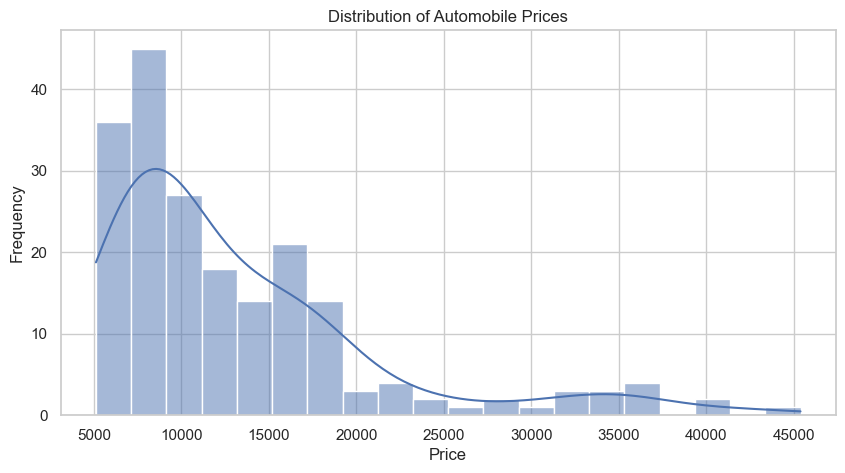

In [41]:
# Distribution of automobile prices

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='price',
    bins=20,
    kde=True
)

plt.title('Distribution of Automobile Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.show()

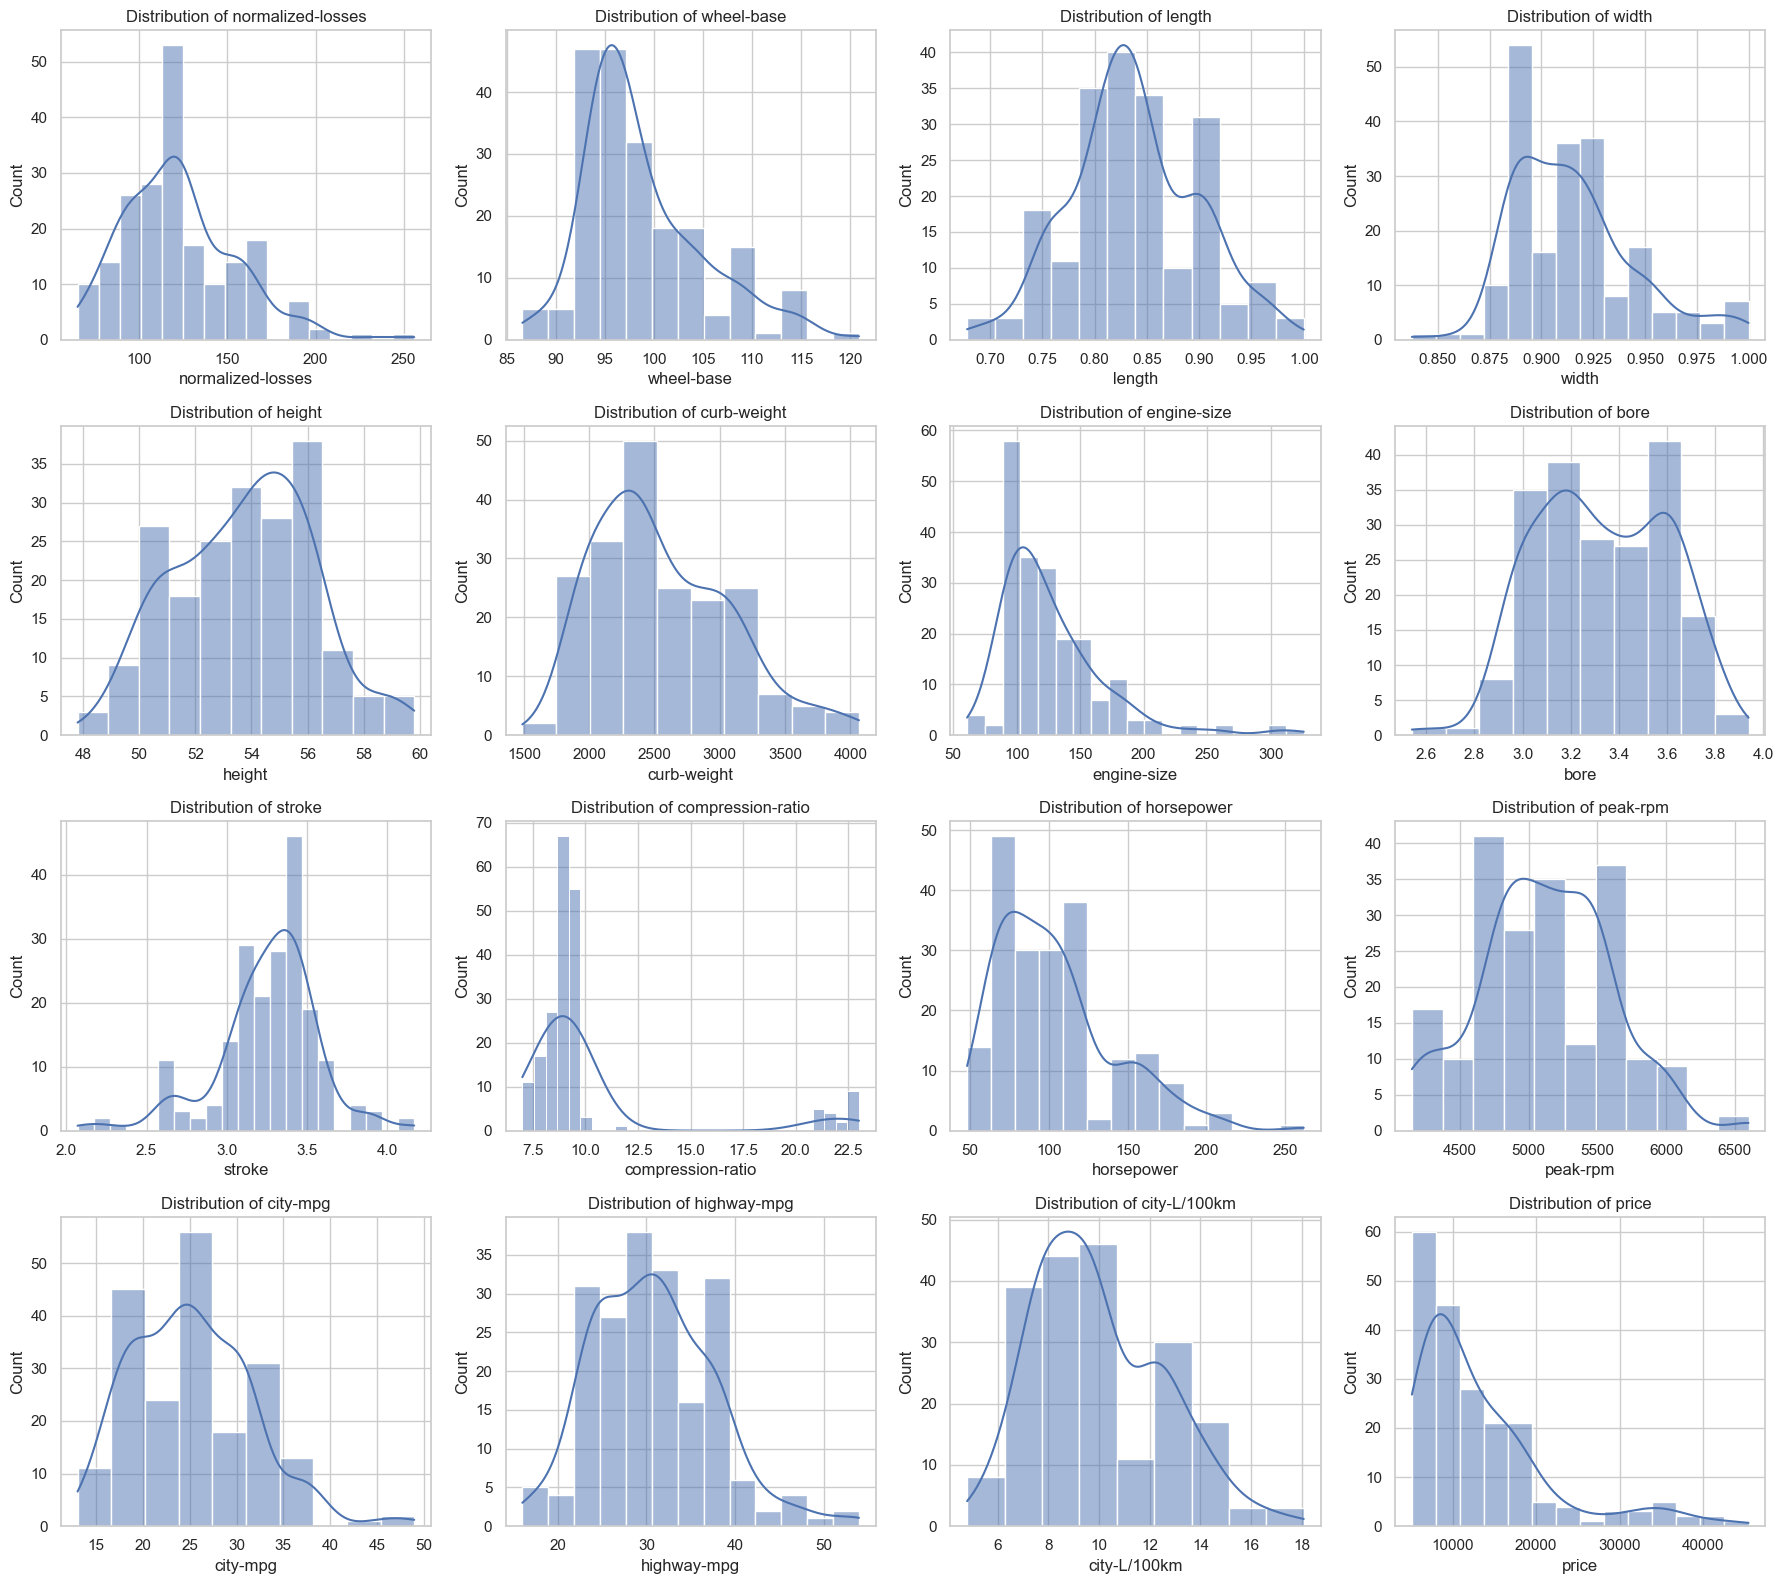

In [40]:
# Plot distributions of continuous variables

fig, axes = plt.subplots(4, 4, figsize=(18, 16))

axes = axes.flatten()

for i, column in enumerate(continuous_vars):

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

The analysis of numerical variables revealed considerable variation in automobile characteristics. Automobile prices, engine size, horsepower, curb weight and wheel base generally show positively skewed distributions, indicating that most vehicles have relatively moderate values, while a smaller proportion have considerably higher measurements. Other variables, including height, width, stroke and peak RPM, show more concentrated distributions. The compression ratio and bore distributions exhibit multiple concentrations, suggesting differences in engine configurations across vehicles.

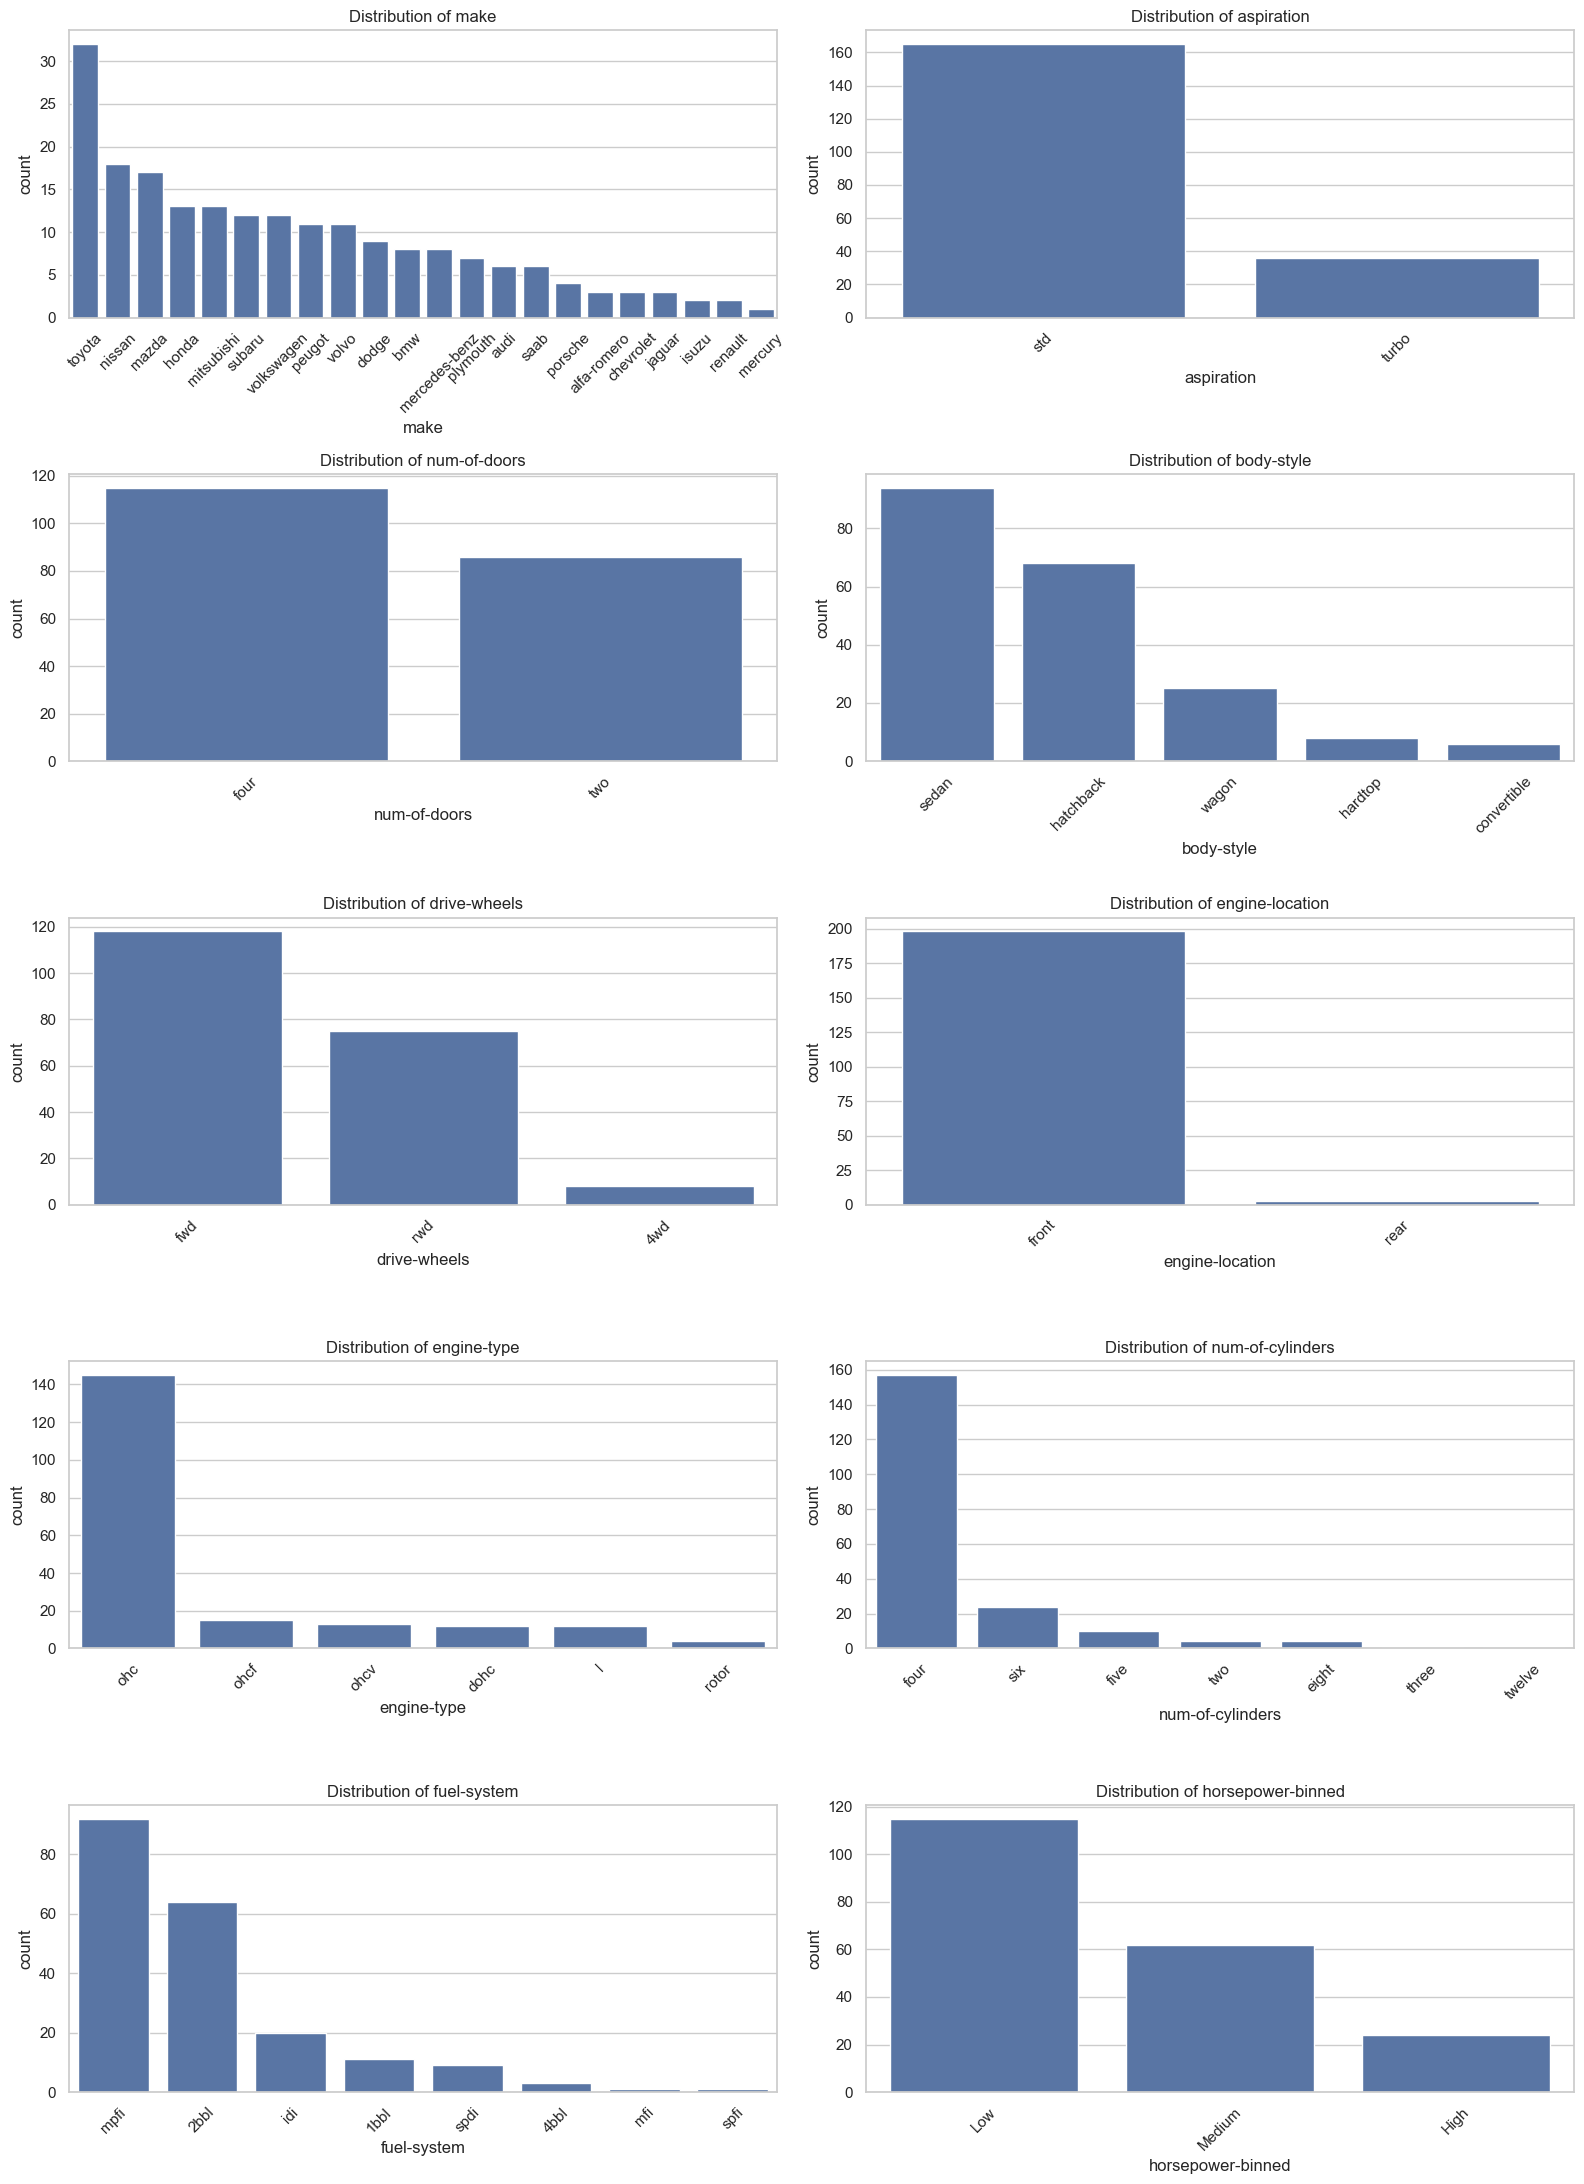

In [82]:
# Plot categorical variable distributions

fig, axes = plt.subplots(5, 2, figsize=(16, 22))

axes = axes.flatten()

for i, column in enumerate(categorical_columns):

    sns.countplot(
        data=df,
        x=column,
        ax=axes[i],
        order=df[column].value_counts().index
    )

    axes[i].set_title(f'Distribution of {column}')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

The categorical distributions show that the dataset is not evenly distributed across most variables. Toyota is the most represented manufacturer, while standard aspiration, four-door body configurations, sedans, front-wheel drive, front-engine vehicles, OHC engines, four-cylinder engines, MPFI fuel systems and low-horsepower vehicles dominate the observations. Some categories, particularly rear-engine vehicles, convertibles, hardtops, and vehicles with three or twelve cylinders, have very few observations. 

# Question 3

In [56]:
#Average price by drive-wheel configuration
drive_wheels_price = df.groupby('drive-wheels').agg(
    average_price=('price', 'mean'),
    median_price=('price', 'median'),
    number_of_cars=('price', 'count'),
    std_price=('price', 'std')
).round(2)

drive_wheels_price.sort_values(by='average_price', ascending=False)

,average_price,median_price,number_of_cars,std_price
drive-wheels,,,,
rwd,19757.61,16900.0,75,9082.58
4wd,10241.00,9005.5,8,3288.21
fwd,9244.78,8192.0,118,3345.90


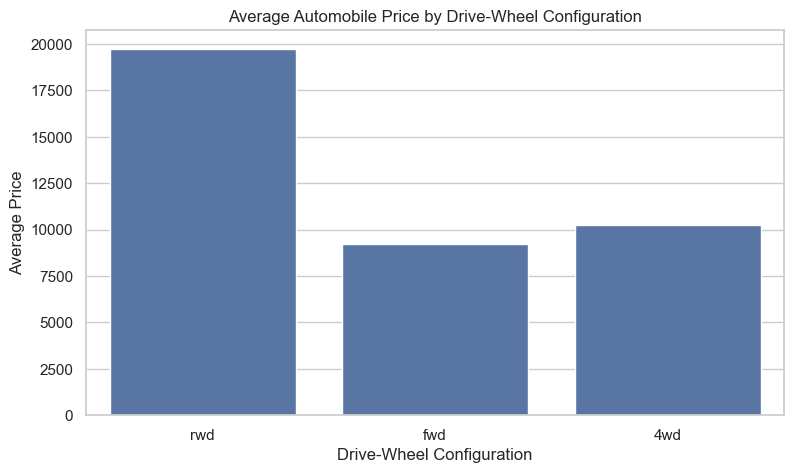

In [48]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='drive-wheels',
    y='price',
    estimator='mean',
    errorbar=None
)

plt.title('Average Automobile Price by Drive-Wheel Configuration')
plt.xlabel('Drive-Wheel Configuration')
plt.ylabel('Average Price')

plt.show()

The analysis reveals differences in average automobile prices across drive-wheel configurations. Rear-wheel-drive (RWD) vehicles have the highest average price of 19,757.61, followed by four-wheel-drive (4WD) vehicles at 10,241.00. Front-wheel-drive (FWD) vehicles have the lowest average price of 9,244.78. The median prices follow a similar pattern, with RWD vehicles recording the highest median of 16,900, compared to 9,005.50 for 4WD and 8,192 for FWD.

In [49]:
#Average price by body style
#Average price by drive-wheel configuration
body_style_price = df.groupby('body-style').agg(
    average_price=('price', 'mean'),
    median_price=('price', 'median'),
    number_of_cars=('price', 'count'),
    std_price=('price', 'std')
).round(2)

body_style_price.sort_values(by='average_price', ascending=False)

,average_price,median_price,number_of_cars,std_price
body-style,,,,
hardtop,22208.50,19687.5,8,14555.52
convertible,21890.50,17084.5,6,11187.80
sedan,14459.76,11078.5,94,8523.21
wagon,12371.96,11694.0,25,5120.95
hatchback,9957.44,8672.0,68,4148.86


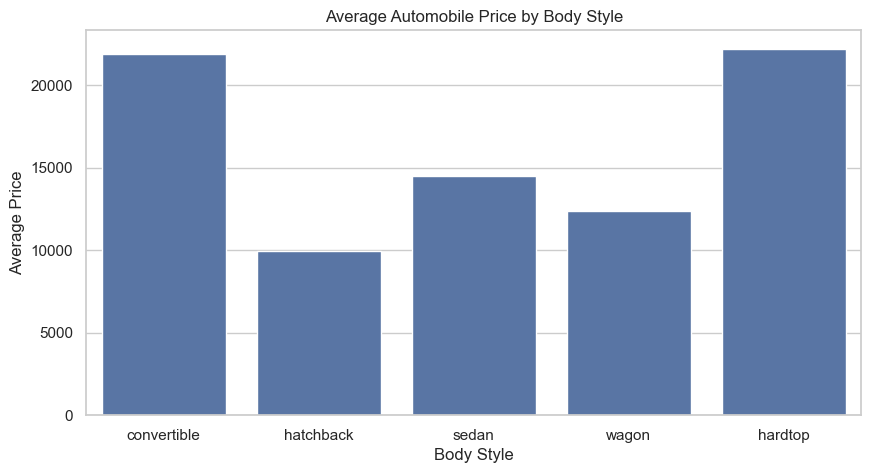

In [51]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='body-style',
    y='price',
    estimator='mean',
    errorbar=None,
)

plt.title('Average Automobile Price by Body Style')
plt.xlabel('Body Style')
plt.ylabel('Average Price')

plt.show()

The analysis reveals  differences in average automobile prices across body styles. Hardtops have the highest average price of 22,208.50, followed closely by convertibles at 21,890.50. Sedans have an average price of 14,459.76, while wagons average 12,371.96. Hatchbacks have the lowest average price at 9,957.44.
The results suggest that automobiles with hardtop and convertible body styles tend to be more expensive than conventional body styles such as sedans, wagons and hatchbacks. 

# Question 4

In [60]:
continuous_variables = [
    'normalized-losses','wheel-base','length',
    'width','height','curb-weight',
    'engine-size','bore','stroke',
    'compression-ratio','horsepower',
    'peak-rpm','city-mpg','highway-mpg','city-L/100km'
]

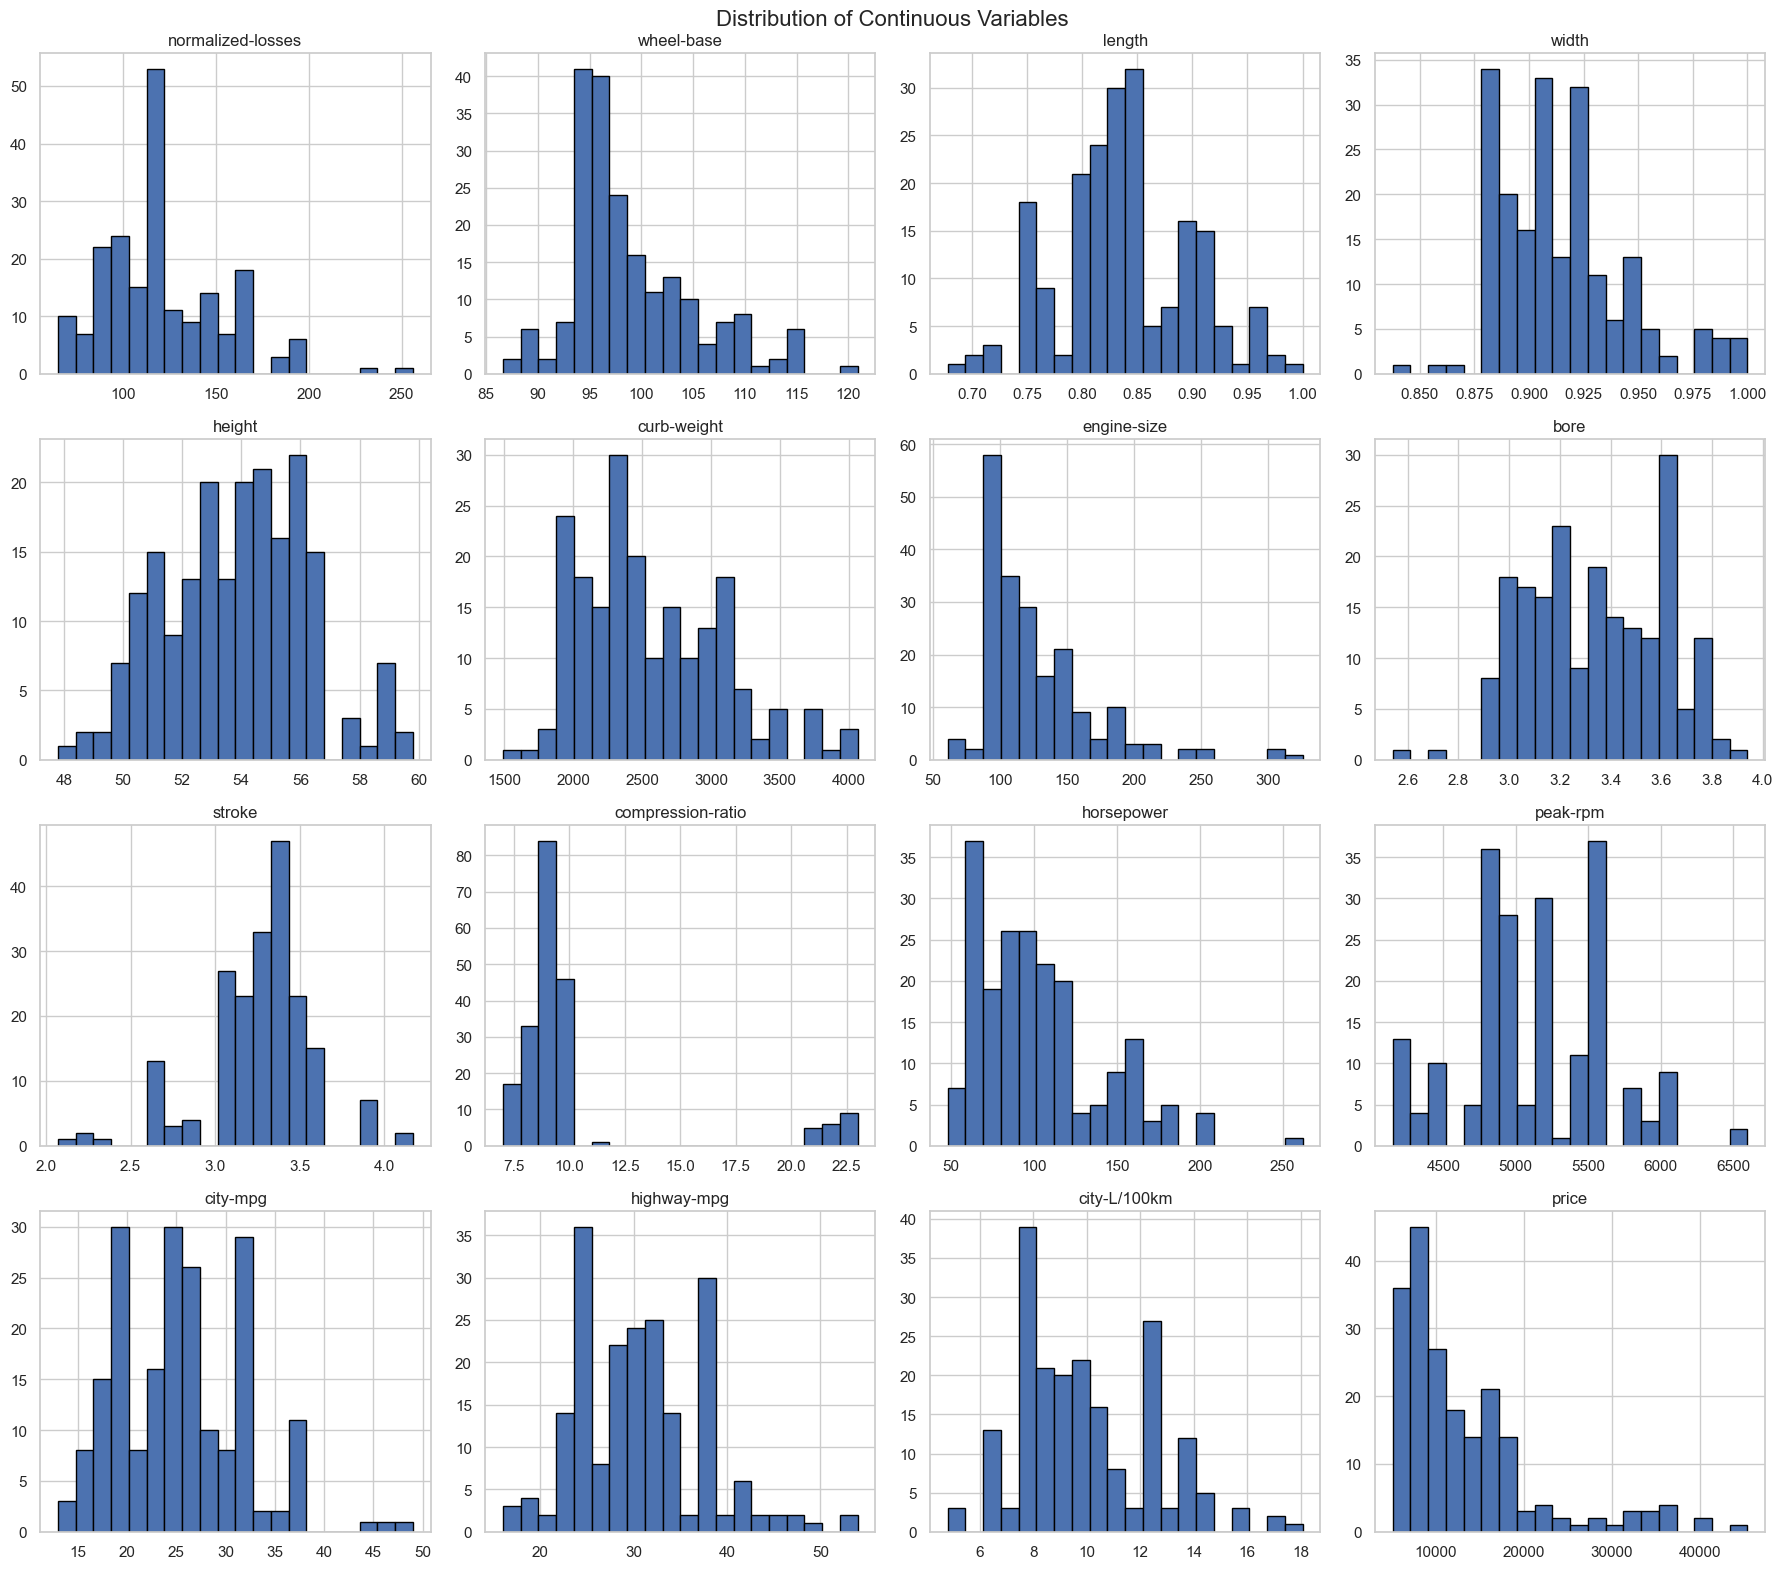

In [61]:

# Include price alongside the independent variables
variables_to_plot = continuous_variables + ['price']

# Plot histograms
df[variables_to_plot].hist(
    figsize=(18, 16),
    bins=20,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Continuous Variables',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [63]:
from scipy.stats import shapiro

normality_results = []

for variable in variables_to_plot:

    statistic, p_value = shapiro(df[variable].dropna())

    normality_results.append({
        'Variable': variable,
        'Shapiro Statistic': statistic,
        'P-value': p_value,
        'Normality': (
            'Approximately normal'
            if p_value > 0.05
            else 'Not normally distributed'
        )
    })

normality_df = pd.DataFrame(normality_results)

normality_df.round(4)

,Variable,Shapiro Statistic,P-value,Normality
0,normalized-losses,0.9507,0.0000,Not normally distributed
1,wheel-base,0.9133,0.0000,Not normally distributed
2,length,0.9816,0.0098,Not normally distributed
3,width,0.9237,0.0000,Not normally distributed
4,height,0.9840,0.0218,Not normally distributed
5,curb-weight,0.9525,0.0000,Not normally distributed
6,engine-size,0.8267,0.0000,Not normally distributed
7,bore,0.9661,0.0001,Not normally distributed
8,stroke,0.9369,0.0000,Not normally distributed
9,compression-ratio,0.4965,0.0000,Not normally distributed


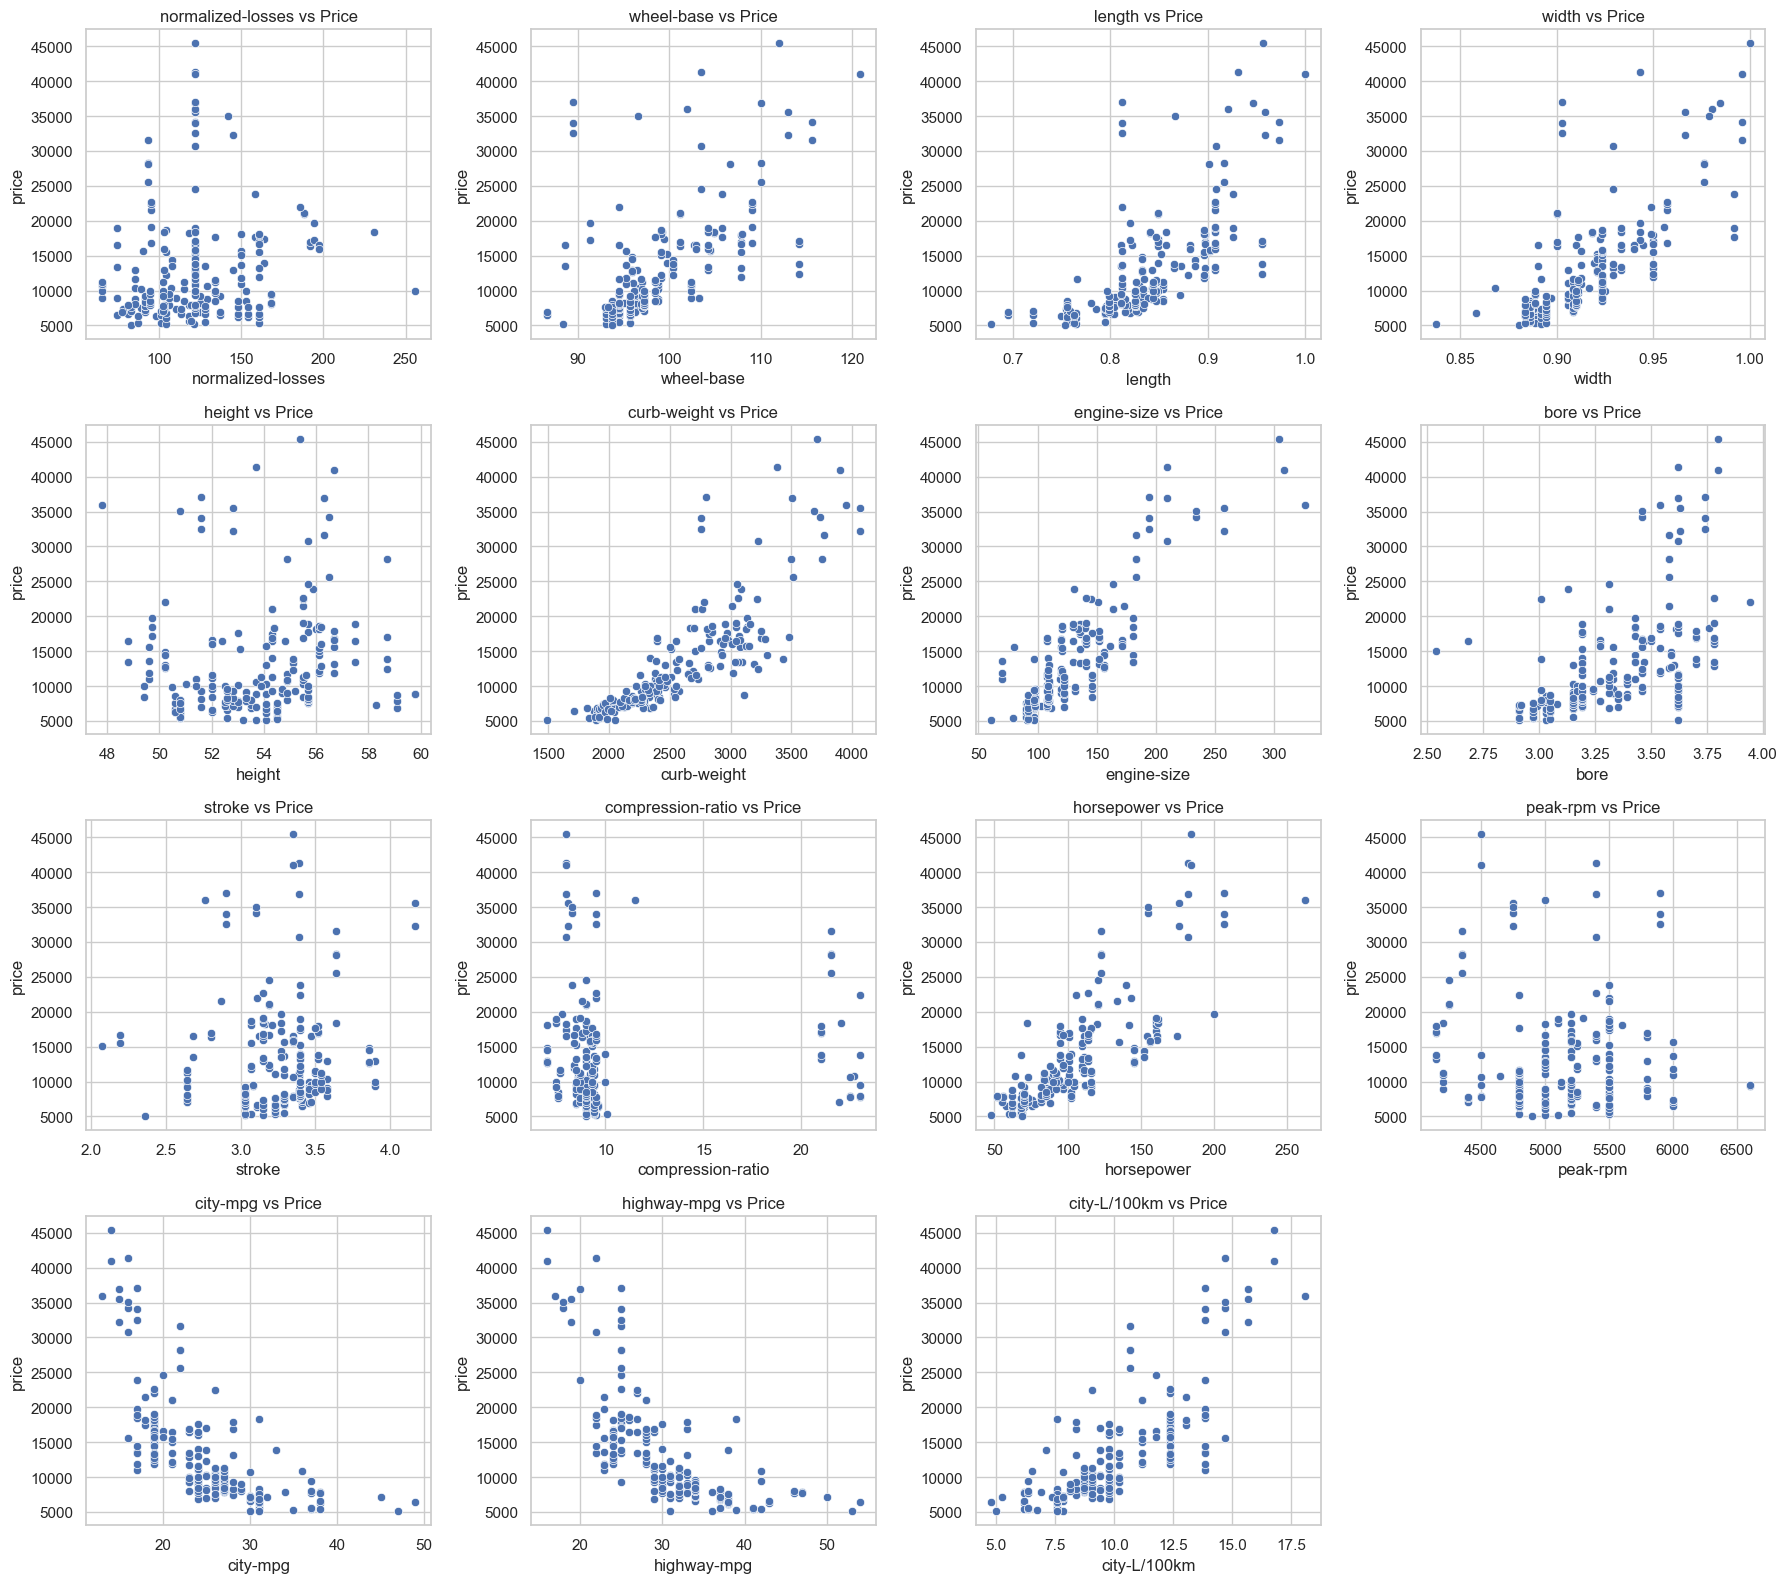

In [64]:
fig, axes = plt.subplots(4, 4, figsize=(18, 16))

for i, variable in enumerate(continuous_variables):
    row = i // 4
    col = i % 4

    sns.scatterplot(
        data=df,
        x=variable,
        y='price',
        ax=axes[row, col]
    )

    axes[row, col].set_title(f'{variable} vs Price')

# Remove the unused final subplot
fig.delaxes(axes[3, 3])

plt.tight_layout()
plt.show()

In [65]:
from scipy.stats import pearsonr, spearmanr
correlation_results = []

for variable in continuous_variables:

    temp = df[[variable, 'price']].dropna()

    pearson_r, pearson_p = pearsonr(temp[variable], temp['price'])
    spearman_rho, spearman_p = spearmanr(temp[variable], temp['price'])

    correlation_results.append({
        'Variable': variable,
        'Pearson r': pearson_r,
        'Pearson p-value': pearson_p,
        'Spearman rho': spearman_rho,
        'Spearman p-value': spearman_p
    })

correlation_df = pd.DataFrame(correlation_results)

# Sort by the absolute strength of Spearman correlation
correlation_df['Absolute Spearman'] = correlation_df['Spearman rho'].abs()

correlation_df = correlation_df.sort_values(
    by='Absolute Spearman',
    ascending=False
)

correlation_df.round(4)

,Variable,Pearson r,Pearson p-value,Spearman rho,Spearman p-value,Absolute Spearman
5,curb-weight,0.8344,0.0000,0.9138,0.0000,0.9138
10,horsepower,0.8096,0.0000,0.8491,0.0000,0.8491
12,city-mpg,-0.6866,0.0000,-0.8313,0.0000,0.8313
14,city-L/100km,0.7899,0.0000,0.8313,0.0000,0.8313
6,engine-size,0.8723,0.0000,0.8284,0.0000,0.8284
13,highway-mpg,-0.7047,0.0000,-0.8273,0.0000,0.8273
3,width,0.7513,0.0000,0.8121,0.0000,0.8121
2,length,0.6906,0.0000,0.8103,0.0000,0.8103
1,wheel-base,0.5846,0.0000,0.6818,0.0000,0.6818
7,bore,0.5432,0.0000,0.6459,0.0000,0.6459


Continuous variables versus price

The relationship between continuous independent variables and car price was examined using scatterplots, Pearson correlation and Spearman rank correlation. The Shapiro–Wilk test indicated that none of the continuous variables, including price, followed a normal distribution at the 5% significance level. Therefore, greater emphasis was placed on Spearman correlation, which measures monotonic relationships and is suitable for assessing associations when variables are not normally distributed.

The results revealed strong positive associations between car price and curb weight (ρ = 0.9138), horsepower (ρ = 0.8491), engine size (ρ = 0.8284), width (ρ = 0.8121) and length (ρ = 0.8103). This suggests that heavier, more powerful, larger-engine and larger-sized vehicles generally have higher prices. Conversely, city-mpg (ρ = -0.8313) and highway-mpg (ρ = -0.8273) had strong negative associations with price, indicating that vehicles with higher fuel efficiency tend to have lower prices in this dataset. City fuel consumption measured in litres per 100 kilometres had a strong positive association (ρ = 0.8313).

Wheel-base (ρ = 0.6818) and bore (ρ = 0.6459) also had positive associations with price, although these were weaker than those of the leading variables. Height and normalized losses had weak positive associations, while compression ratio had a very weak negative association. Stroke and peak-rpm did not show statistically significant relationships with price at the 5% level.

Overall, the findings suggest that vehicle weight, engine performance, physical dimensions and fuel economy are important characteristics associated with car prices. 

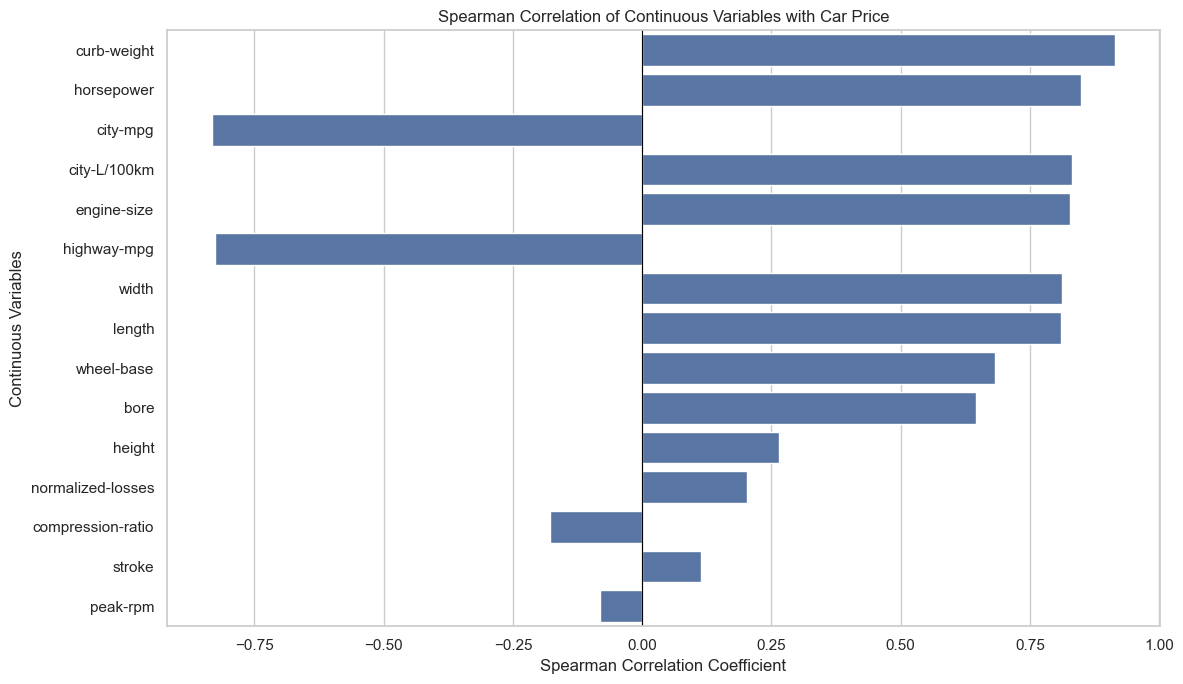

In [66]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=correlation_df,
    x='Spearman rho',
    y='Variable'
)

plt.axvline(0, color='black', linewidth=0.8)
plt.title('Spearman Correlation of Continuous Variables with Car Price')
plt.xlabel('Spearman Correlation Coefficient')
plt.ylabel('Continuous Variables')
plt.tight_layout()
plt.show()

# 4b


In [67]:
categorical_variables = [
    'make','aspiration','num-of-doors',
    'body-style','drive-wheels','engine-location',
    'engine-type','num-of-cylinders','fuel-system',
    'horsepower-binned'
]

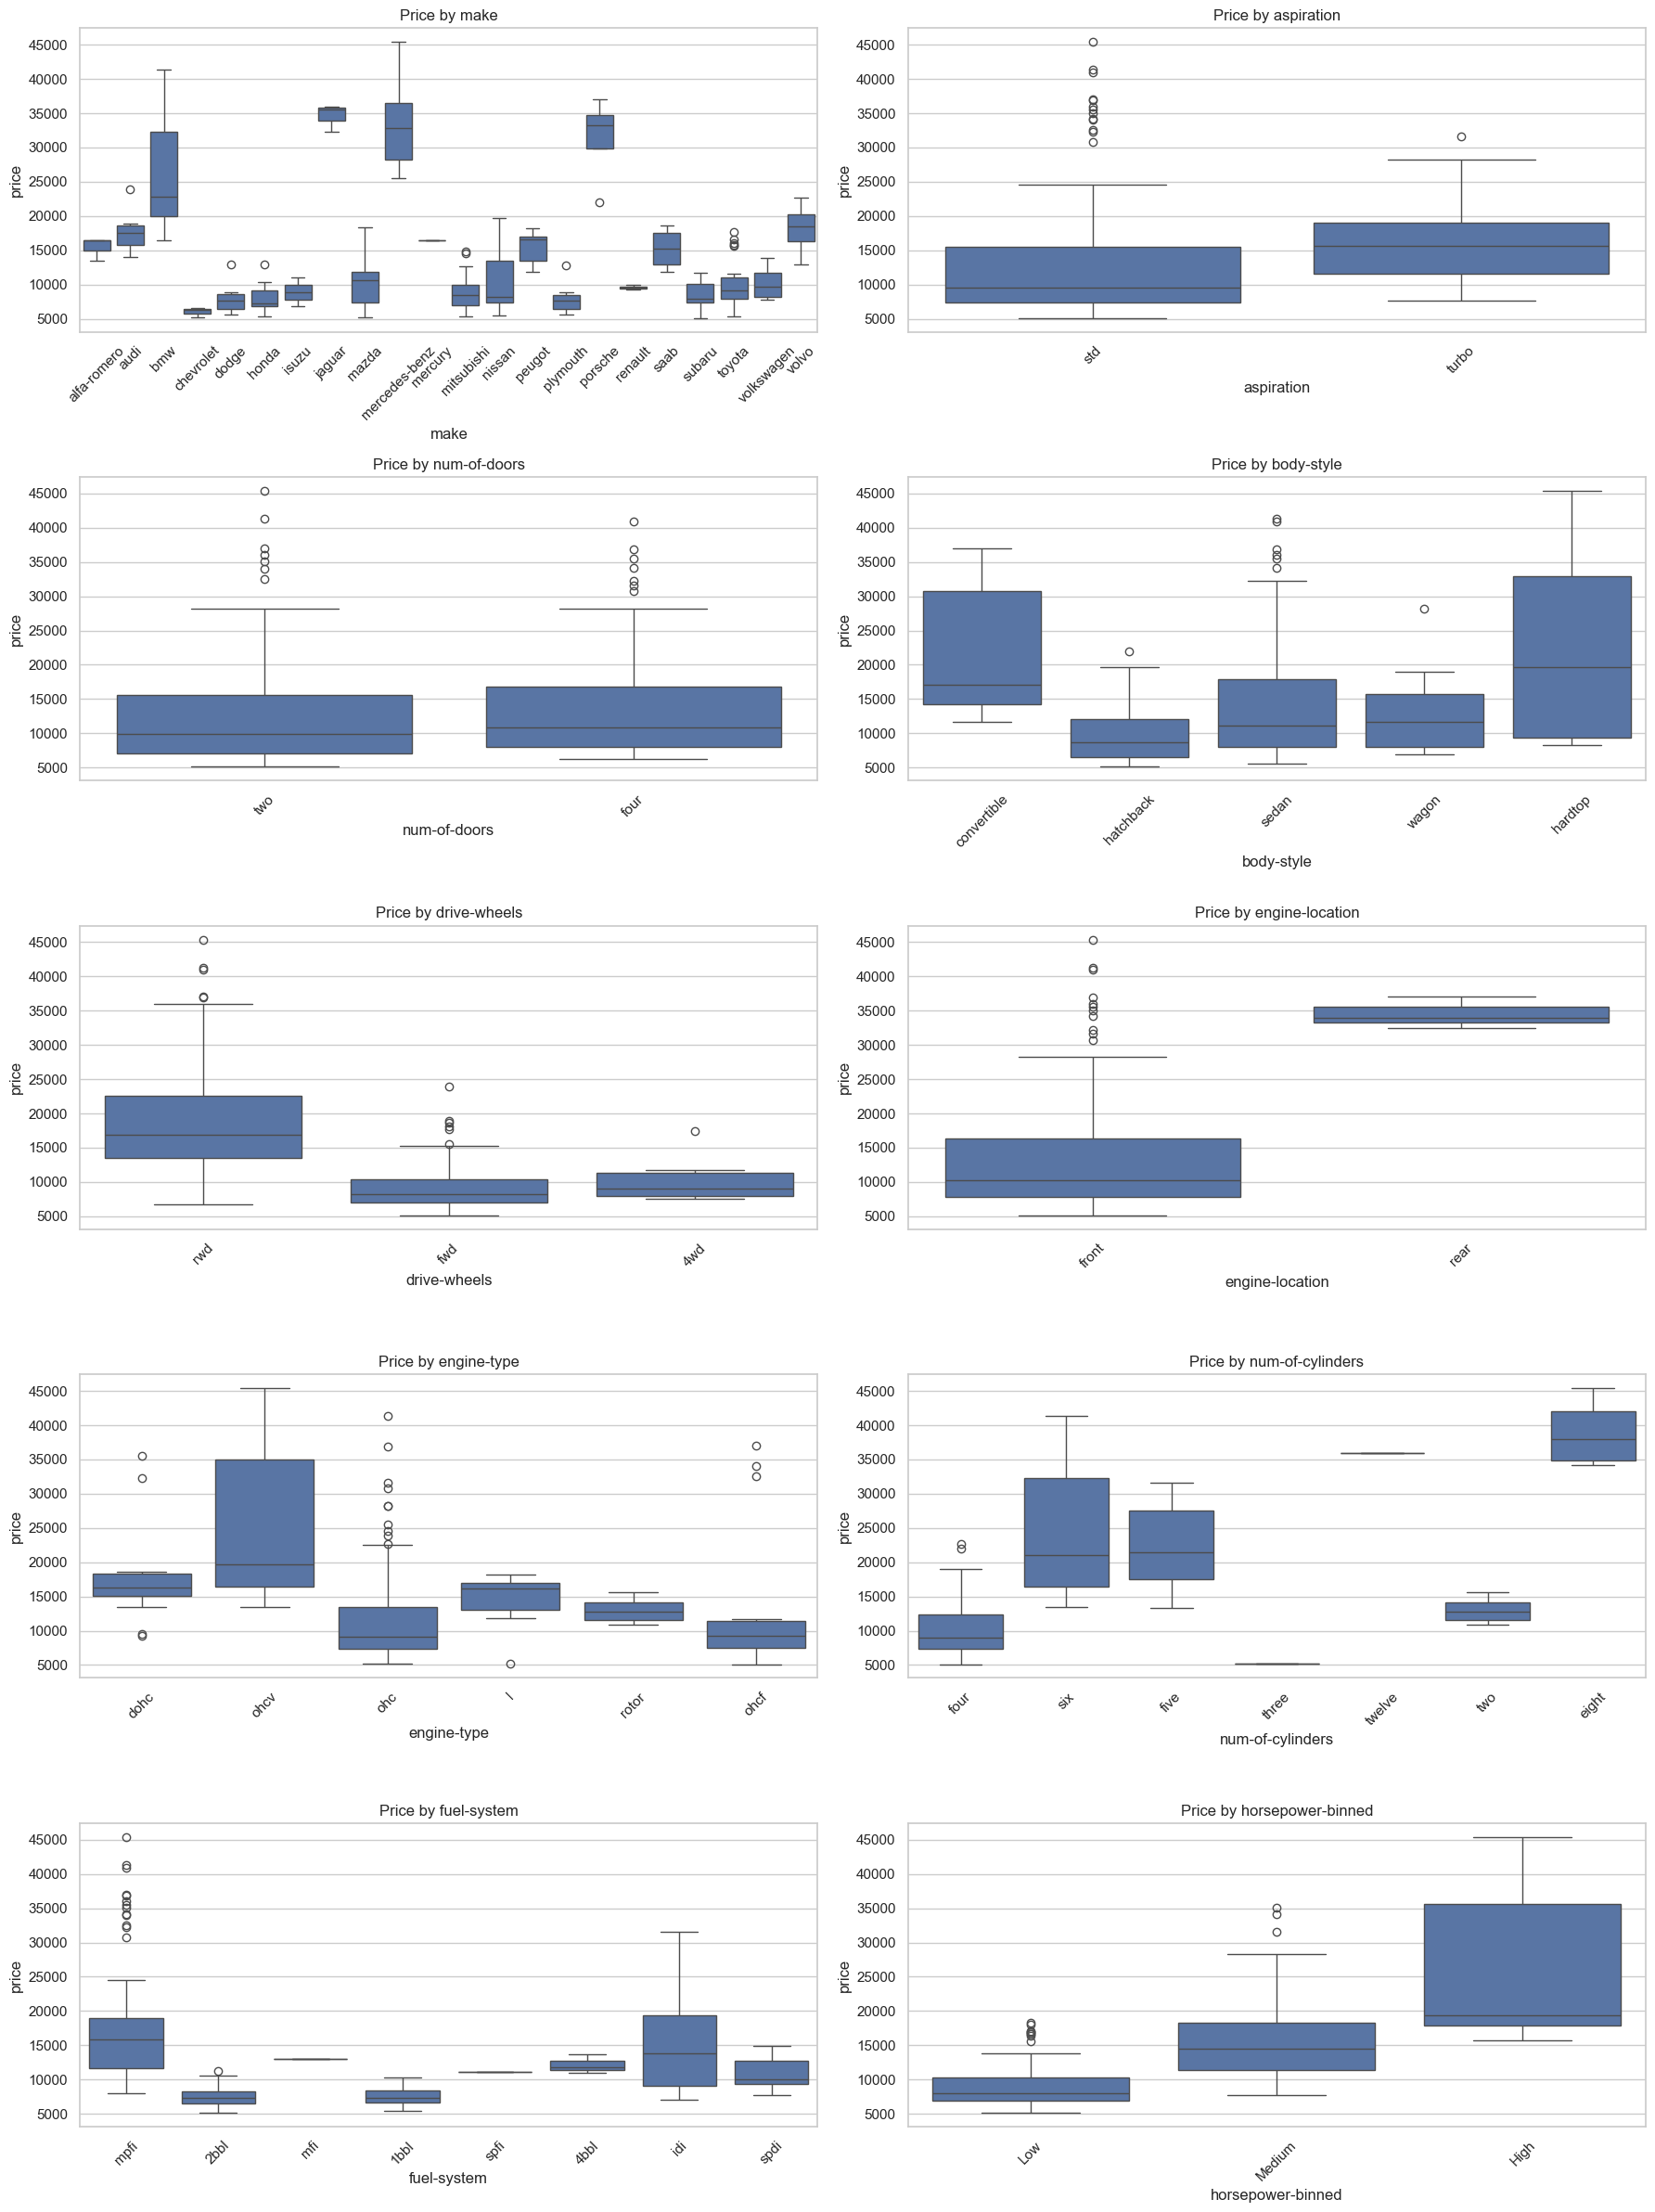

In [68]:
fig, axes = plt.subplots(5, 2, figsize=(18, 24))

for i, variable in enumerate(categorical_variables):
    row = i // 2
    col = i % 2

    sns.boxplot(
        data=df,
        x=variable,
        y='price',
        ax=axes[row, col]
    )

    axes[row, col].set_title(f'Price by {variable}')
    axes[row, col].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [69]:
for variable in categorical_variables:

    print(f'\nPrice statistics by {variable}')

    display(
        df.groupby(variable)['price']
        .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
        .sort_values('mean', ascending=False)
        .round(2)
    )


Price statistics by make


,count,mean,median,std,min,max
make,,,,,,
jaguar,3,34600.00,35550.0,2047.56,32250,36000
mercedes-benz,8,33647.00,32892.0,6789.56,25552,45400
porsche,4,31400.50,33278.0,6528.78,22018,37028
bmw,8,26118.75,22835.0,9263.83,16430,41315
volvo,11,18063.18,18420.0,3314.65,12940,22625
audi,6,17859.17,17580.0,3452.38,13950,23875
mercury,1,16503.00,16503.0,NaN,16503,16503
alfa-romero,3,15498.33,16500.0,1734.94,13495,16500
peugot,11,15489.09,16630.0,2246.75,11900,18150



Price statistics by aspiration


,count,mean,median,std,min,max
aspiration,,,,,,
turbo,36,16254.81,15686.0,6179.62,7689,31600
std,165,12542.18,9538.0,8147.75,5118,45400



Price statistics by num-of-doors


,count,mean,median,std,min,max
num-of-doors,,,,,,
four,115,13498.03,10898.0,7340.34,6229,40960
two,86,12818.13,9927.0,8721.88,5118,45400


... (10 outputs left out)


Price statistics by fuel-system


,count,mean,median,std,min,max
fuel-system,,,,,,
mpfi,92,17605.14,15867.5,8662.21,7957,45400
idi,20,15838.15,13852.5,7759.84,7099,31600
mfi,1,12964.00,12964.0,NaN,12964,12964
4bbl,3,12145.00,11845.0,1374.77,10945,13645
spfi,1,11048.00,11048.0,NaN,11048,11048
spdi,9,10990.44,9959.0,2741.73,7689,14869
1bbl,11,7555.55,7295.0,1390.12,5399,10295
2bbl,64,7433.20,7324.0,1382.90,5118,11245



Price statistics by horsepower-binned


,count,mean,median,std,min,max
horsepower-binned,,,,,,
High,24,26320.00,19372.0,10150.02,15690,45400
Medium,62,15913.02,14444.0,6498.87,7689,35056
Low,115,9011.70,7999.0,3078.53,5118,18344


In [70]:
from scipy.stats import kruskal
import pandas as pd

kruskal_results = []

for variable in categorical_variables:

    groups = [
        group['price'].values
        for _, group in df.groupby(variable)
    ]

    statistic, p_value = kruskal(*groups)

    kruskal_results.append({
        'Variable': variable,
        'H-statistic': statistic,
        'P-value': p_value,
        'Conclusion': (
            'Significant difference'
            if p_value < 0.05
            else 'No significant difference'
        )
    })

kruskal_df = pd.DataFrame(kruskal_results)

kruskal_df.round(4)

,Variable,H-statistic,P-value,Conclusion
0,make,124.2139,0.0000,Significant difference
1,aspiration,18.7574,0.0000,Significant difference
2,num-of-doors,3.4195,0.0644,No significant difference
3,body-style,25.0231,0.0000,Significant difference
4,drive-wheels,93.1889,0.0000,Significant difference
5,engine-location,7.7293,0.0054,Significant difference
6,engine-type,38.0393,0.0000,Significant difference
7,num-of-cylinders,80.8646,0.0000,Significant difference
8,fuel-system,122.5969,0.0000,Significant difference
9,horsepower-binned,103.2578,0.0000,Significant difference


The relationship between categorical variables and car price was examined using boxplots, descriptive statistics and the Kruskal–Wallis H-test. The Kruskal–Wallis test was selected because the Shapiro–Wilk results indicated that price was not normally distributed. The results showed statistically significant differences in price across most categorical variables, including make, aspiration, body style, drive wheels, engine location, engine type, number of cylinders, fuel system and horsepower category (p less than 0.05). The number of doors was the only variable that did not show a statistically significant difference in price (H = 3.4195, p = 0.0644). The descriptive statistics and boxplots further showed that some categories had higher average prices than others. For example, rear-engine vehicles, cars with eight cylinders and turbocharged vehicles generally had higher average prices in this dataset. However, some categories had very few observations, so their results should be interpreted cautiously. Overall, the findings suggest that several vehicle characteristics are associated with differences in car prices.

# 4c

In [71]:
# Create a contingency table
contingency_table = pd.crosstab(
    df['body-style'],
    df['drive-wheels']
)

contingency_table

drive-wheels,4wd,fwd,rwd
body-style,,,
convertible,0,1,5
hardtop,0,1,7
hatchback,1,49,18
sedan,3,55,36
wagon,4,12,9


In [72]:
# Calculate row percentages
row_percentages = pd.crosstab(
    df['body-style'],
    df['drive-wheels'],
    normalize='index'
) * 100

row_percentages.round(2)

drive-wheels,4wd,fwd,rwd
body-style,,,
convertible,0.00,16.67,83.33
hardtop,0.00,12.50,87.50
hatchback,1.47,72.06,26.47
sedan,3.19,58.51,38.30
wagon,16.00,48.00,36.00


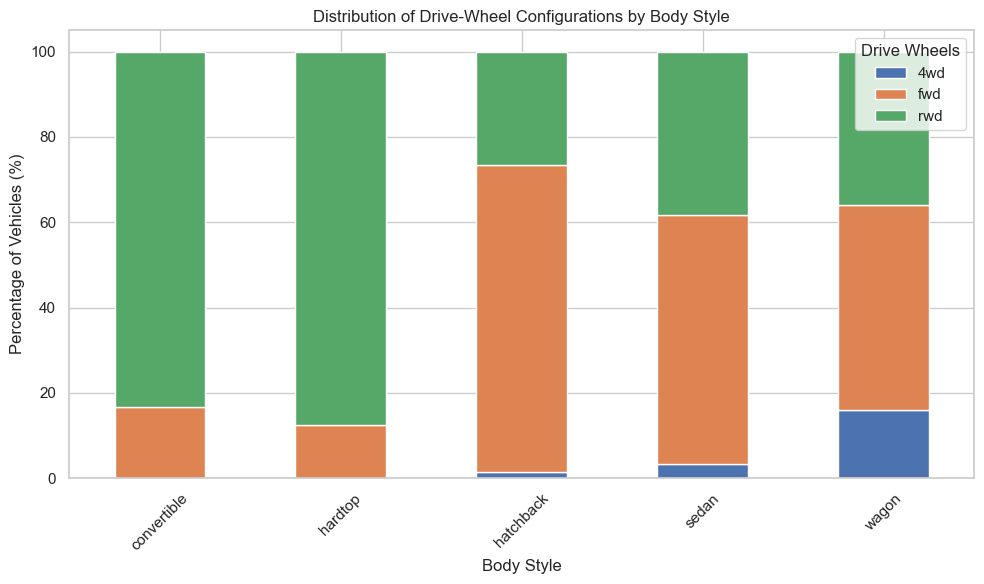

In [73]:
row_percentages.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Distribution of Drive-Wheel Configurations by Body Style')
plt.xlabel('Body Style')
plt.ylabel('Percentage of Vehicles (%)')
plt.legend(title='Drive Wheels')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [74]:
from scipy.stats import chi2_contingency

chi2, p_value, degrees_of_freedom, expected_frequencies = (
    chi2_contingency(contingency_table)
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of freedom: {degrees_of_freedom}")

# Examine expected frequencies
expected_table = pd.DataFrame(
    expected_frequencies,
    index=contingency_table.index,
    columns=contingency_table.columns
)

expected_table.round(2)

Chi-square statistic: 29.1087
P-value: 0.0003
Degrees of freedom: 8


drive-wheels,4wd,fwd,rwd
body-style,,,
convertible,0.24,3.52,2.24
hardtop,0.32,4.70,2.99
hatchback,2.71,39.92,25.37
sedan,3.74,55.18,35.07
wagon,1.00,14.68,9.33


In [75]:
from scipy.stats import chi2_contingency, MonteCarloMethod
chi2, p_value, degrees_of_freedom, expected_frequencies = (
    chi2_contingency(
        contingency_table,
        correction=False,
        method=MonteCarloMethod(n_resamples=100000, rng=np.random.default_rng(42))
    )
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Monte Carlo p-value: {p_value:.4f}")

Chi-square statistic: 29.1087
Monte Carlo p-value: 0.0029


The relationship between two categorical variables, body style and drive-wheel configuration, was examined using cross-tabulation, a stacked bar chart and the Chi-square test of independence. The descriptive results showed differences in drive-wheel configurations across body styles. For example, 83.33% of convertibles and 87.50% of hardtops were rear-wheel drive, while 72.06% of hatchbacks were front-wheel drive. The initial Chi-square test produced a statistic of 29.1087 and a p-value of 0.0003. However, the expected frequencies were too small to satisfy the assumptions of the conventional Chi-square approximation. Therefore, a Monte Carlo approximation was used, producing a p-value of 0.0029. Since this is below the 5% significance level, the null hypothesis of independence was rejected. The findings indicate a statistically significant association between body style and drive-wheel configuration.

# Question 5

In [76]:
# Remove the target and redundant engineered variables
columns_to_exclude = [
    'price',
    'horsepower-binned',
    'city-L/100km',
    'gas'
]

X = df.drop(
    columns=[col for col in columns_to_exclude if col in df.columns]
)

y = df['price']

print("Number of predictors:", X.shape[1])
print("Number of observations:", X.shape[0])

Number of predictors: 25
Number of observations: 201


In [78]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score

# Identify numerical and categorical predictors
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(
    include=['object', 'category', 'str']
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_features),

        ('numerical', 'passthrough', numeric_features)
    ]
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Training observations: 160
Testing observations: 41


In [79]:
# Create the model pipeline
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        min_samples_leaf=2
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error: {mae:.2f}")
print(f"R-squared: {r2:.4f}")

Mean Absolute Error: 1872.51
R-squared: 0.9334


In [80]:
# Calculate permutation importance
importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring='r2'
)

# Create importance dataframe
feature_importance = pd.DataFrame({
    'Variable': X_test.columns,
    'Importance': importance.importances_mean,
    'Std': importance.importances_std
})

# Sort from most to least important
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.round(4)

,Variable,Importance,Std
15,engine-size,0.3619,0.0503
12,curb-weight,0.2977,0.0566
20,horsepower,0.0257,0.0039
10,width,0.0176,0.0032
23,highway-mpg,0.0132,0.0027
22,city-mpg,0.0103,0.0022
9,length,0.0045,0.0009
8,wheel-base,0.0036,0.0012
2,make,0.0025,0.0016
19,compression-ratio,0.0019,0.0004


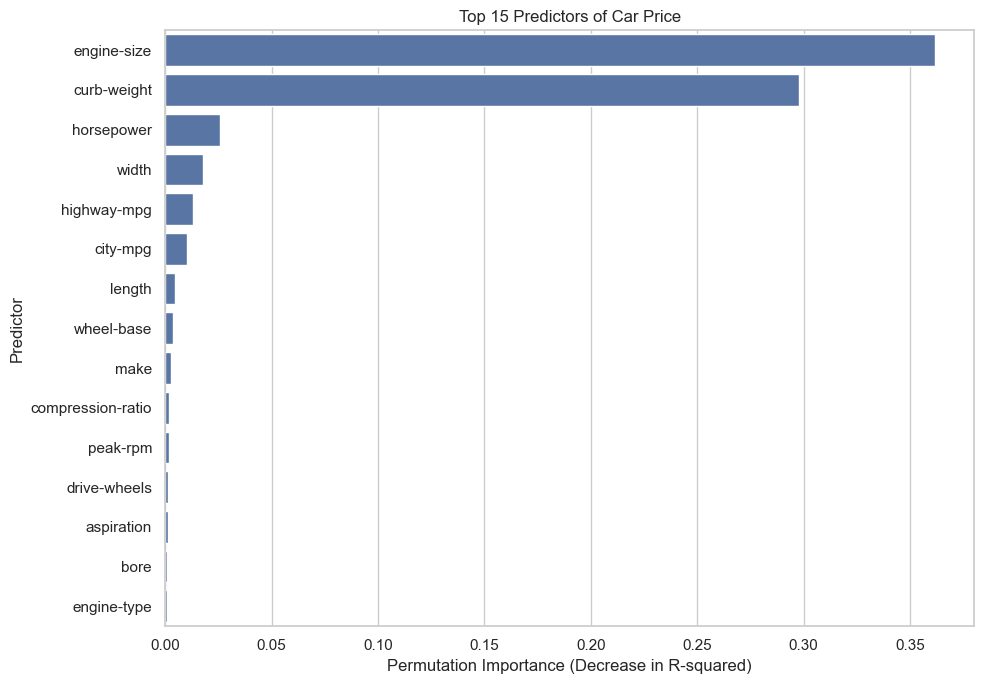

In [81]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Variable'
)

plt.title('Top 15 Predictors of Car Price')
plt.xlabel('Permutation Importance (Decrease in R-squared)')
plt.ylabel('Predictor')
plt.tight_layout()
plt.show()

A Random Forest Regression model was used to identify the most important variables influencing car prices. The model was evaluated using an 80:20 training and testing split. Its performance was assessed using Mean Absolute Error (MAE) and the coefficient of determination (R-squared). The model achieved an MAE of 1,872.51 and an R-squared of 0.9334, indicating that it explained approximately 93.34% of the variation in car prices in the test dataset.

Permutation feature importance was subsequently used to identify the main predictors. Engine size had the highest importance score (0.3619), followed by curb weight (0.2977). Other relevant predictors included horsepower (0.0257), width (0.0176), highway fuel economy (0.0132) and city fuel economy (0.0103). These findings suggest that engine specifications and vehicle physical characteristics are particularly important in predicting car prices.

Recommendation to a car dealer
A car dealer should prioritise engine size and curb weight when determining vehicle prices, as these were the two most important predictors identified by the Random Forest model. Vehicles with larger engines and higher specifications may command higher prices, although their condition, mileage, age and market demand should also be considered. The dealer should use the model as a guide when estimating prices, while comparing similar vehicles in the market to ensure that the final selling price is competitive and realistic.